<a href="https://colab.research.google.com/github/luckyKumar37/Deep_learning_project/blob/main/animal%20face%20classifier/animal_face_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install kagglehub --quiet
import kagglehub
import os


path = kagglehub.dataset_download("andrewmvd/animal-faces")
print("Path to dataset files:", path)
symlink_path = "/content/animal-faces"
if not os.path.exists(symlink_path):
    os.symlink(path, symlink_path)
    print(f"Created symbolic link: {symlink_path} -> {path}")
else:
    print(f"Symbolic link or folder already exists at {symlink_path}")

100%|██████████| 696M/696M [00:05<00:00, 133MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/andrewmvd/animal-faces/versions/1
Created symbolic link: /content/animal-faces -> /root/.cache/kagglehub/datasets/andrewmvd/animal-faces/versions/1


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset,Dataset,DataLoader,random_split
from torchvision import datasets,transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import os
from PIL import Image


def set_seed(seed=42):
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  random.seed(seed)
  np.random.seed(seed)


set_seed()

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
def get_data_loaders(data_dir, batch_size=32):
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])


    train_dir = os.path.join(data_dir, 'afhq', 'train')
    val_dir = os.path.join(data_dir, 'afhq', 'val')

    train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transform)
    val_dataset = datasets.ImageFolder(root=val_dir, transform=val_transform)



    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    print(f"Train size: {len(train_dataset)} images across classes: {train_dataset.classes}")
    print(f"Val size: {len(val_dataset)} images across classes: {val_dataset.classes}")

    return train_dataset, val_dataset, train_loader, val_loader, train_dataset.classes


train_dataset, val_dataset,train_loader, val_loader, class_names = get_data_loaders(symlink_path)

Train size: 14630 images across classes: ['cat', 'dog', 'wild']
Val size: 1500 images across classes: ['cat', 'dog', 'wild']


In [4]:
image,label = train_dataset[0]
print(image.shape)

torch.Size([3, 224, 224])


In [5]:
class model(nn.Module):
  def __init__(self, input_size, num_classes=3):
     super().__init__()

     self.extraction = nn.Sequential(
         nn.Conv2d(input_size, 32, kernel_size=3, padding='same'),
         nn.ReLU(),
         nn.BatchNorm2d(32),
         nn.MaxPool2d(kernel_size=2, stride=2),

         nn.Conv2d(32, 64, kernel_size=3, padding='same'),
         nn.ReLU(),
         nn.BatchNorm2d(64),
         nn.MaxPool2d(kernel_size=2, stride=2),

         nn.Conv2d(64, 128, kernel_size=3, padding='same'),
         nn.ReLU(),
         nn.BatchNorm2d(128),
         nn.MaxPool2d(kernel_size=2, stride=2)
     )

     self.classification = nn.Sequential(
         nn.Flatten(),
         nn.Linear(128*28*28, 256),
         nn.ReLU(),
         nn.Dropout(0.3),
         nn.Linear(256, 128),
         nn.ReLU(),
         nn.Dropout(0.4),
         nn.Linear(128,num_classes)
     )

  def forward(self, x):
     x = self.extraction(x)
     x = self.classification(x)
     return x

In [6]:
model = model(3).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(params=model.parameters(),lr=1e-3)


In [7]:
from torchsummary import summary


summary(model,input_size=(3,224,224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 224, 224]             896
              ReLU-2         [-1, 32, 224, 224]               0
       BatchNorm2d-3         [-1, 32, 224, 224]              64
         MaxPool2d-4         [-1, 32, 112, 112]               0
            Conv2d-5         [-1, 64, 112, 112]          18,496
              ReLU-6         [-1, 64, 112, 112]               0
       BatchNorm2d-7         [-1, 64, 112, 112]             128
         MaxPool2d-8           [-1, 64, 56, 56]               0
            Conv2d-9          [-1, 128, 56, 56]          73,856
             ReLU-10          [-1, 128, 56, 56]               0
      BatchNorm2d-11          [-1, 128, 56, 56]             256
        MaxPool2d-12          [-1, 128, 28, 28]               0
          Flatten-13               [-1, 100352]               0
           Linear-14                  [

In [9]:
total_train_loss = []
total_val_loss = []
total_train_acc = []
total_val_acc = []

epochs = 10

for epoch in range(epochs):
  train_loss = 0
  train_acc = 0

  val_loss = 0
  val_acc = 0

  model.train()

  for images,labels in train_loader:

    images, labels = images.to(device),labels.to(device)

    prediction = model(images)

    loss = criterion(prediction,labels)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    train_loss += loss.item()

    acc = (torch.argmax(prediction,axis = 1) == labels).sum().item()

    train_acc += acc


  model.eval()

  with torch.no_grad():

    for images,labels in val_loader:

        images, labels = images.to(device),labels.to(device)

        prediction = model(images)

        loss = criterion(prediction,labels)

        val_loss += loss.item() # Use .item() to extract the scalar float value

        acc = (torch.argmax(prediction,axis=1) == labels).sum().item()

        val_acc += acc

  total_train_loss.append(round(train_loss/len(train_loader),4))
  total_val_loss.append(round(val_loss/len(val_loader),4))
  total_train_acc.append(round(train_acc/(len(train_dataset))*100,4))
  total_val_acc.append(round(val_acc/(len(val_dataset))*100,4))

  print(f'''Epoch {epoch+1}/{epochs}, Train Loss: {round(train_loss/len(train_loader), 4)} Train Accuracy {round((train_acc)/len(train_dataset)* 100, 4)}
              Validation Loss: {round(val_loss/len(val_loader), 4)} Validation Accuracy: {round((val_acc)/len(val_dataset) * 100, 4)}''')
  print("="*25)

Epoch 1/10, Train Loss: 0.1758 Train Accuracy 93.7662
              Validation Loss: 0.1714 Validation Accuracy: 94.2667
Epoch 2/10, Train Loss: 0.1168 Train Accuracy 96.0424
              Validation Loss: 0.2026 Validation Accuracy: 93.2667
Epoch 3/10, Train Loss: 0.093 Train Accuracy 96.8011
              Validation Loss: 0.1002 Validation Accuracy: 97.0667
Epoch 4/10, Train Loss: 0.0807 Train Accuracy 97.4573
              Validation Loss: 0.0864 Validation Accuracy: 97.1333
Epoch 5/10, Train Loss: 0.0722 Train Accuracy 97.758
              Validation Loss: 0.094 Validation Accuracy: 97.5333
Epoch 6/10, Train Loss: 0.0643 Train Accuracy 97.9904
              Validation Loss: 0.1119 Validation Accuracy: 97.2
Epoch 7/10, Train Loss: 0.0597 Train Accuracy 98.2023
              Validation Loss: 0.0818 Validation Accuracy: 97.9333
Epoch 8/10, Train Loss: 0.0645 Train Accuracy 98.1681
              Validation Loss: 0.1112 Validation Accuracy: 97.8667
Epoch 9/10, Train Loss: 0.0463 Train A

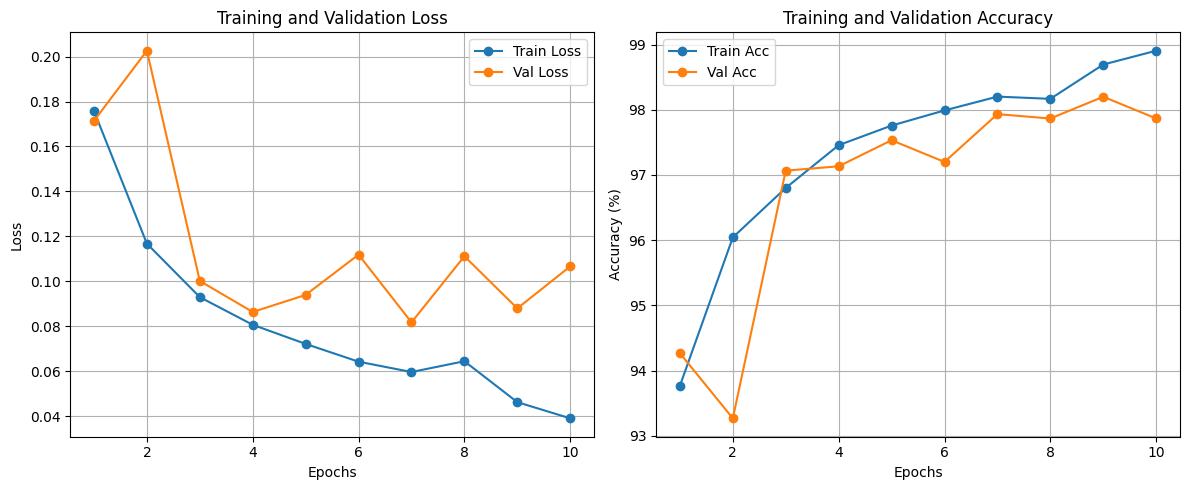

In [10]:
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), total_train_loss, label='Train Loss', marker='o')
plt.plot(range(1, epochs + 1), total_val_loss, label='Val Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), total_train_acc, label='Train Acc', marker='o')
plt.plot(range(1, epochs + 1), total_val_acc, label='Val Acc', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
